In [1]:
# Phase 3: Credit Risk Exploratory Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project root is the parent of the notebooks directory
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "credit_risk_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully
Shape: (32581, 12)
Columns: ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Visualization setup complete")

Visualization setup complete


,count,percentage
loan_status,,
0,25473,78.18
1,7108,21.82


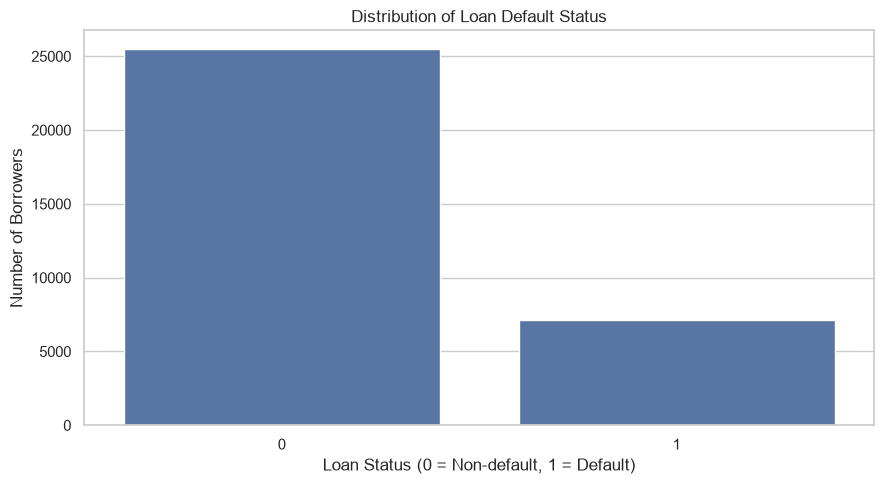

In [3]:
target_counts = df["loan_status"].value_counts().sort_index()
target_percentages = (
    df["loan_status"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages.round(2)
})

display(target_summary)

ax = sns.countplot(data=df, x="loan_status")
ax.set_title("Distribution of Loan Default Status")
ax.set_xlabel("Loan Status (0 = Non-default, 1 = Default)")
ax.set_ylabel("Number of Borrowers")

plt.tight_layout()
plt.show()

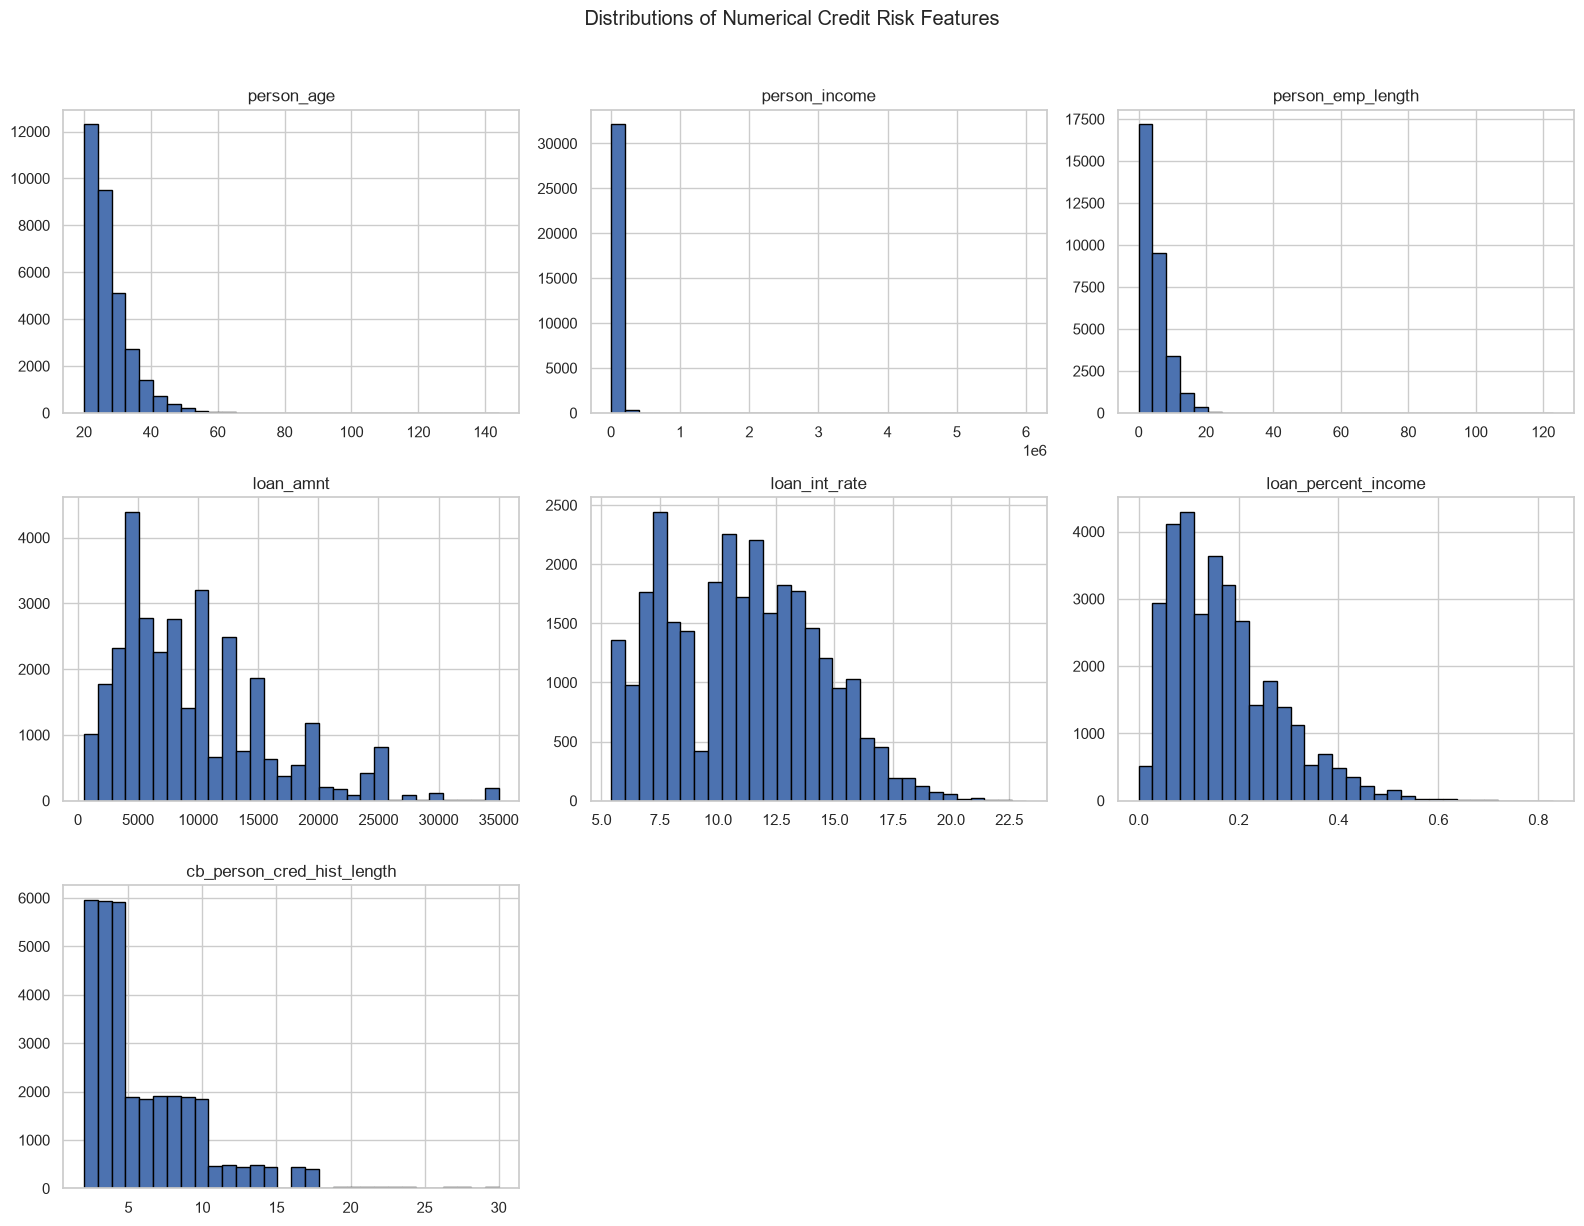

In [4]:
numerical_columns = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

df[numerical_columns].hist(
    bins=30,
    figsize=(16, 12),
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Credit Risk Features", y=1.02)
plt.tight_layout()
plt.show()

In [5]:
# Compact EDA summary for review

print("=== DATASET ===")
print("Shape:", df.shape)

print("\n=== TARGET DISTRIBUTION ===")
print(
    (df["loan_status"].value_counts(normalize=True)
     .sort_index() * 100).round(2).to_dict()
)

print("\n=== NUMERICAL SUMMARY ===")
display(
    df[numerical_columns]
    .describe()
    .round(2)
)

print("\n=== DEFAULT RATE BY CATEGORY ===")
for col in [
    "loan_grade",
    "loan_intent",
    "person_home_ownership",
    "cb_person_default_on_file"
]:
    print(f"\n{col}")
    display(
        df.groupby(col, dropna=False)["loan_status"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "default_rate"})
        .assign(default_rate=lambda x: (x["default_rate"] * 100).round(2))
        .sort_values("default_rate", ascending=False)
    )

=== DATASET ===
Shape: (32581, 12)

=== TARGET DISTRIBUTION ===
{0: 78.18, 1: 21.82}

=== NUMERICAL SUMMARY ===


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,0.83,30.00



=== DEFAULT RATE BY CATEGORY ===

loan_grade


,count,default_rate
loan_grade,,
G,64,98.44
F,241,70.54
E,964,64.42
D,3626,59.05
C,6458,20.73
B,10451,16.28
A,10777,9.96



loan_intent


,count,default_rate
loan_intent,,
DEBTCONSOLIDATION,5212,28.59
MEDICAL,6071,26.70
HOMEIMPROVEMENT,3605,26.10
PERSONAL,5521,19.89
EDUCATION,6453,17.22
VENTURE,5719,14.81



person_home_ownership


,count,default_rate
person_home_ownership,,
RENT,16446,31.57
OTHER,107,30.84
MORTGAGE,13444,12.57
OWN,2584,7.47



cb_person_default_on_file


,count,default_rate
cb_person_default_on_file,,
Y,5745,37.81
N,26836,18.39


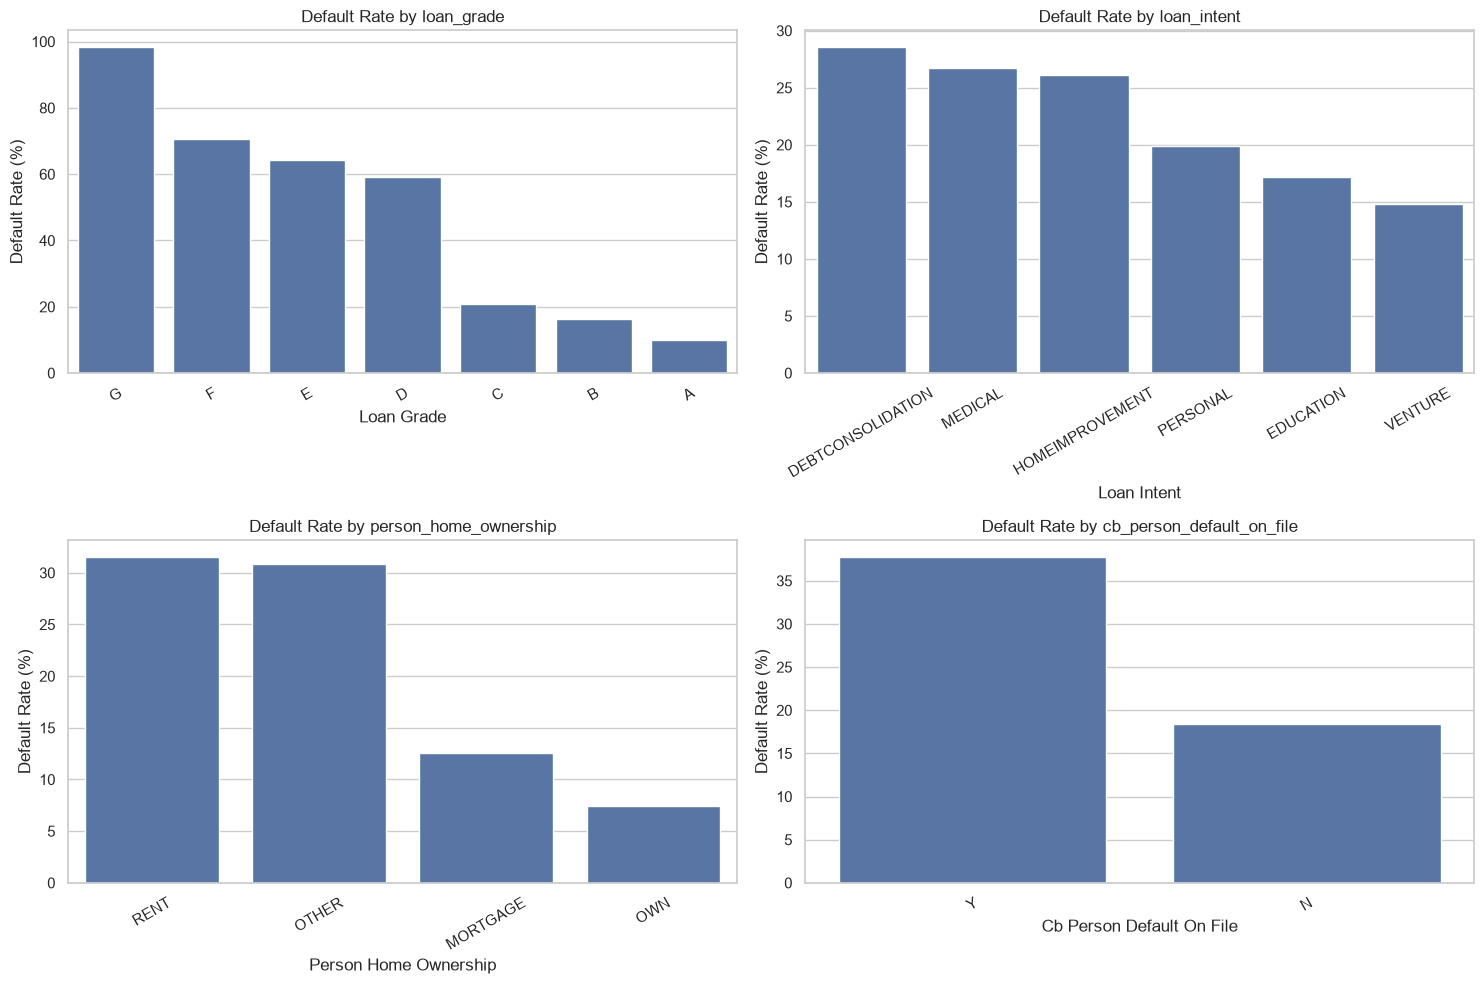

In [6]:
# Phase 3: Categorical default-rate visualizations

categorical_cols = [
    "loan_grade",
    "loan_intent",
    "person_home_ownership",
    "cb_person_default_on_file"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col, ax in zip(categorical_cols, axes.flat):
    rates = (
        df.groupby(col, observed=False)["loan_status"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=rates.index,
        y=rates.values,
        ax=ax
    )

    ax.set_title(f"Default Rate by {col}")
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Default Rate (%)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

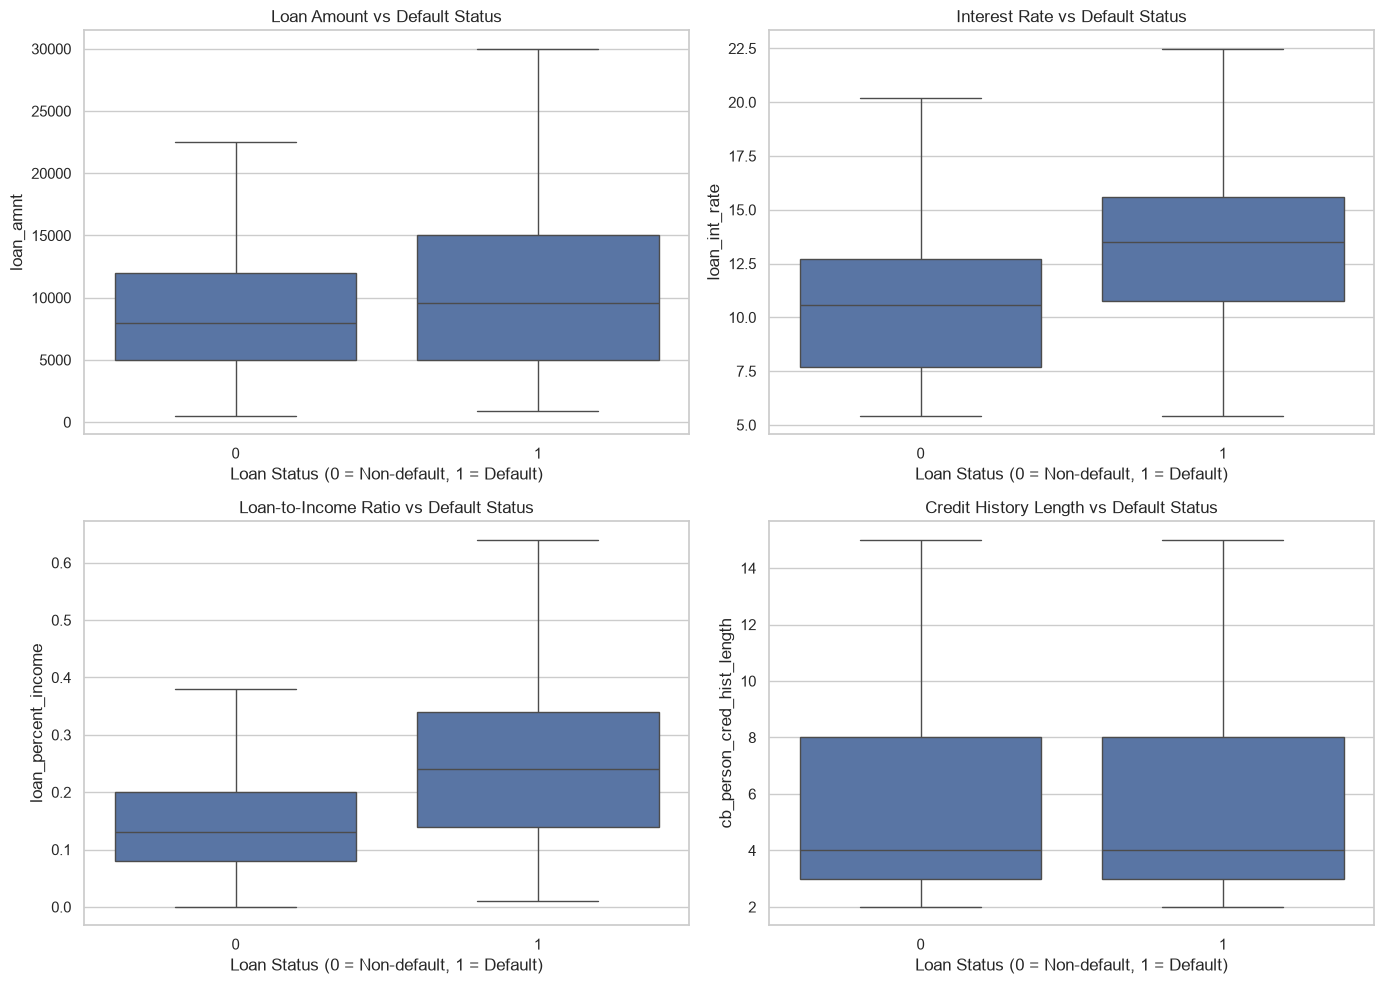

In [7]:
# Phase 3: Numerical features vs loan default

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Loan amount by default status
sns.boxplot(
    data=df, x="loan_status", y="loan_amnt",
    showfliers=False, ax=axes[0, 0]
)
axes[0, 0].set_title("Loan Amount vs Default Status")
axes[0, 0].set_xlabel("Loan Status (0 = Non-default, 1 = Default)")

# 2. Interest rate by default status
sns.boxplot(
    data=df, x="loan_status", y="loan_int_rate",
    showfliers=False, ax=axes[0, 1]
)
axes[0, 1].set_title("Interest Rate vs Default Status")
axes[0, 1].set_xlabel("Loan Status (0 = Non-default, 1 = Default)")

# 3. Loan-to-income ratio by default status
sns.boxplot(
    data=df, x="loan_status", y="loan_percent_income",
    showfliers=False, ax=axes[1, 0]
)
axes[1, 0].set_title("Loan-to-Income Ratio vs Default Status")
axes[1, 0].set_xlabel("Loan Status (0 = Non-default, 1 = Default)")

# 4. Credit history length by default status
sns.boxplot(
    data=df, x="loan_status", y="cb_person_cred_hist_length",
    showfliers=False, ax=axes[1, 1]
)
axes[1, 1].set_title("Credit History Length vs Default Status")
axes[1, 1].set_xlabel("Loan Status (0 = Non-default, 1 = Default)")

plt.tight_layout()
plt.show()

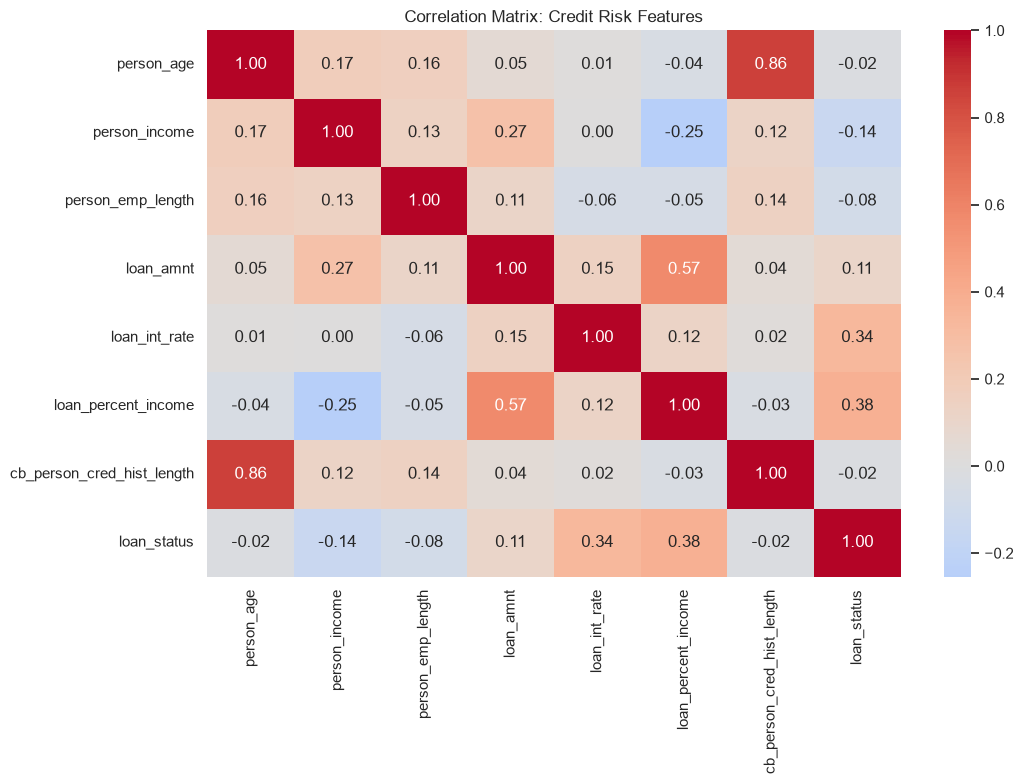

In [8]:
# Correlation among numerical features

correlation_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "loan_status"
]

correlation_matrix = df[correlation_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix: Credit Risk Features")
plt.tight_layout()
plt.show()

# Phase 3: Exploratory Data Analysis — Findings

## 1. Target Distribution
The dataset contains 32,581 loan records. Approximately 78.18% are non-default cases and 21.82% are default cases. The target is moderately imbalanced, so model evaluation should include precision, recall, F1-score, ROC-AUC and PR-AUC rather than relying on accuracy alone.

## 2. Loan Grade
Observed default rates increase substantially across riskier loan grades. Grade A has a default rate of 9.96%, while Grade G has a rate of 98.44%. Grade G contains only 64 records, so its rate should be interpreted cautiously. Loan grade may already encode information from a lender's risk assessment; its timing and availability must be checked before using it for prediction.

## 3. Loan Purpose
Debt consolidation has the highest observed default rate among the listed loan purposes at 28.59%, followed by medical loans at 26.70%. Venture loans have the lowest observed rate at 14.81%. These differences describe associations in this dataset and do not establish that loan purpose causes default.

## 4. Home Ownership
Renters have an observed default rate of 31.57%, compared with 12.57% for mortgage holders and 7.47% for the OWN category. The OTHER category has only 107 records, so its estimate is less stable. These relationships may be influenced by income, loan characteristics and other borrower attributes.

## 5. Previous Default History
Borrowers marked Y for previous default history have an observed default rate of 37.81%, compared with 18.39% for borrowers marked N. This feature may provide predictive information, provided it was available at the time of the lending decision.

## 6. Numerical Features and Correlations
Box plots were generated to compare loan amount, interest rate, loan-to-income ratio and credit history length across target classes. A correlation heatmap was also generated for numerical features and the target. These plots should be interpreted as exploratory evidence, not proof of causation.

## 7. Data Quality Considerations
The validation phase identified 4,011 missing values, 165 exact duplicate rows, five records with age above 100, two records with employment length exceeding age, and 283 loan-to-income ratio discrepancies. The raw dataset remains unchanged. These issues will be handled through documented preprocessing before model training.

## 8. Modeling Implications
- Address target imbalance when selecting evaluation metrics and decision thresholds.
- Fit imputers and other learned transformations on training data only.
- Investigate duplicate records before train/test splitting to reduce leakage risk.
- Investigate loan-grade timing and possible leakage before including it in a model.
- Compare the original loan-to-income ratio with a recalculated version.
- Evaluate model performance using metrics appropriate for default detection.

## Conclusion
EDA identified several potentially informative relationships between borrower characteristics, loan attributes and observed default outcomes. These findings guide the next phases of database design and credit risk modeling. Relationships must be validated on held-out data before drawing conclusions about predictive performance.

In [9]:
# Phase 3: Final EDA checks

print("Dataset shape:", df.shape)
print("Target values:", sorted(df["loan_status"].dropna().unique()))
print("Missing values:", int(df.isna().sum().sum()))
print("Default rate (%):", round(df["loan_status"].mean() * 100, 2))

assert df.shape == (32581, 12)
assert set(df["loan_status"].dropna().unique()) == {0, 1}

print("\nPhase 3 EDA checks passed.")

Dataset shape: (32581, 12)
Target values: [np.int64(0), np.int64(1)]
Missing values: 4011
Default rate (%): 21.82

Phase 3 EDA checks passed.
